# 02 — A synthetic 200 mm wafer

We cannot share a real fab's wafer data, so we build a synthetic wafer shaped by published statistics:

* **Junction resistance** is lognormal with a 12.4% spread and a 6.89 kΩ mean
  ([Lang et al., Phys. Rev. Applied 24, 054052 (2025)](https://journals.aps.org/prapplied/abstract/10.1103/42nj-fjg8)).
  We split that spread into a smooth wafer trend, a per-die offset and per-junction noise.
  **The split is our assumption**, because no paper we read publishes it.
* **Layout**: 10 × 7 mm dies (Lang et al., Sec. II) with 4 qubits each
  ([Mayer, Weber et al., arXiv:2505.08424](https://arxiv.org/abs/2505.08424)).
  The 4 mm edge exclusion is our assumption, chosen to land near Lang's ~375 dies.
* **Cryo frequencies** come from Eq. 1 using the wafer's hidden effective T_c and each qubit's true capacitance.
  The capacitance spread (2%) is an assumption. The leftover noise is **tuned** so the prediction error averages ≈ 1.6%,
  the figure reported in arXiv:2505.08424. It is tuned, not derived.

The generator returns two tables: `observed` (what an analyst sees) and `truth` (hidden, used only for scoring).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from yieldkit.wafer import WaferConfig, make_wafer, eq1_prediction_hz, mean_abs_rel_error

cfg = WaferConfig()
observed, truth = make_wafer(cfg, seed=2026)
print(f"{observed.die_id.nunique()} dies, {len(observed)} qubits, {observed.is_cooled.sum()} cooled qubits")
observed.head()

370 dies, 1480 qubits, 40 cooled qubits


,wafer_id,die_id,qubit_id,x_m,y_m,rn_measured_ohm,f01_measured_hz,is_cooled
0,0,0,0,-0.02,-0.0875,7350.312525,NaN,False
1,0,0,1,-0.02,-0.0875,8324.159200,NaN,False
2,0,0,2,-0.02,-0.0875,7889.030710,NaN,False
3,0,0,3,-0.02,-0.0875,7530.612796,NaN,False
4,0,1,0,-0.01,-0.0875,8899.476830,NaN,False


## Wafer map of measured junction resistance

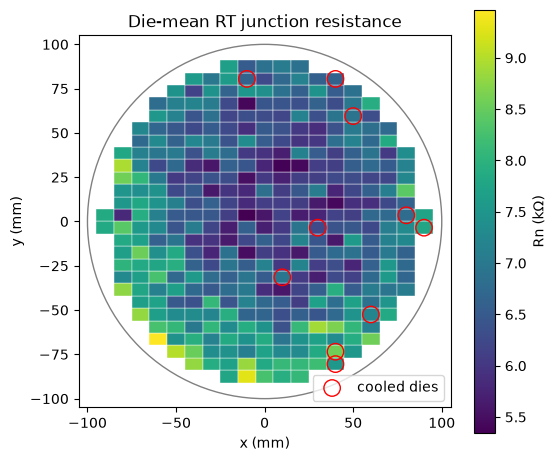

Measured Rn: mean 6.89 kΩ, RSD 12.7%  (Lang et al.: 6.89 kΩ, 12.4%)


In [2]:
die_rn = observed.groupby("die_id").agg(x=("x_m", "first"), y=("y_m", "first"), rn=("rn_measured_ohm", "mean"))
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
w_mm, h_mm = cfg.die_width_m * 1e3, cfg.die_height_m * 1e3
rects = [Rectangle((x * 1e3 - w_mm / 2, y * 1e3 - h_mm / 2), w_mm, h_mm) for x, y in zip(die_rn.x, die_rn.y)]
fig, ax = plt.subplots(figsize=(6, 5.5))
sc = PatchCollection(rects, cmap="viridis", edgecolor="white", linewidth=0.3)
sc.set_array(die_rn.rn.to_numpy() / 1e3)
ax.add_collection(sc)
ax.set_xlim(-105, 105); ax.set_ylim(-105, 105)
ax.add_patch(plt.Circle((0, 0), cfg.wafer_diameter_m / 2 * 1e3, fill=False, color="grey"))
cooled = observed[observed.is_cooled].groupby("die_id")[["x_m", "y_m"]].first()
ax.scatter(cooled.x_m * 1e3, cooled.y_m * 1e3, facecolors="none", edgecolors="red", s=140, label="cooled dies")
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_title("Die-mean RT junction resistance")
fig.colorbar(sc, ax=ax, label="Rn (kΩ)"); ax.legend(loc="lower right")
plt.show()

rn = observed.rn_measured_ohm
print(f"Measured Rn: mean {rn.mean()/1e3:.2f} kΩ, RSD {100*rn.std()/rn.mean():.1f}%  (Lang et al.: 6.89 kΩ, 12.4%)")

## Predicted vs measured frequency (like Fig. 1b of arXiv:2505.08424)

The analyst predicts f₀₁ from the measured R_n using Eq. 1, with T_c = 0.71 K and the design C_q = 86 fF,
then compares against the cryo-measured value on the 10 cooled dies (40 qubits).

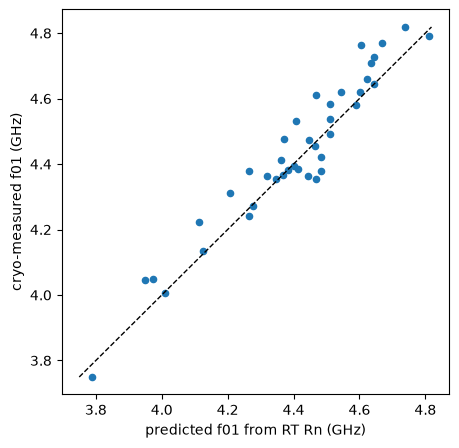

Mean |prediction error| on these 40 qubits: 1.27%  (paper: 1.6%, our noise is tuned to it)


In [3]:
TC_ANALYST = 0.71   # K, Lang et al. fitted value; the analyst does not see the wafer's true Tc
c = observed[observed.is_cooled]
pred = eq1_prediction_hz(c, TC_ANALYST, cfg.cq_design_f)
meas = c.f01_measured_hz.to_numpy()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pred / 1e9, meas / 1e9, s=20)
lo, hi = min(pred.min(), meas.min()) / 1e9, max(pred.max(), meas.max()) / 1e9
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set_xlabel("predicted f01 from RT Rn (GHz)"); ax.set_ylabel("cryo-measured f01 (GHz)")
plt.show()

err = mean_abs_rel_error(observed, TC_ANALYST, cfg.cq_design_f)
print(f"Mean |prediction error| on these {len(c)} qubits: {100*err:.2f}%  (paper: 1.6%, our noise is tuned to it)")

## Sanity check: frequency spread across the wafer

Lang et al. (Sec. IV.2) report a qubit-frequency spread of ≈ 8.4% across the wafer radius. We did **not** tune to this.
Because f₀₁ ∝ 1/√R_n, a 12.4% resistance spread should give roughly 6% before the capacitance spread is added.

In [4]:
f = truth.f01_true_hz
print(f"Our wafer: f01 spread (RSD) = {100*f.std()/f.mean():.1f}%   vs   Lang et al.: ≈ 8.4%")

Our wafer: f01 spread (RSD) = 6.6%   vs   Lang et al.: ≈ 8.4%


**What this means for a fab:** one cheap room-temperature probe pass already predicts each qubit's
frequency to within a couple of percent. The remaining error, and the choice of *which* few dies to cool, is where
a statistical model can help (Step 4).